<a href="https://colab.research.google.com/github/Viji-codes/Credit-card-Fraud-detection/blob/main/Credit_card_fraud_detection.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [16]:
# Credit Card Fraud Detection
# By Vijaya Lakshmi
# Using Machine Learning

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import classification_report
from sklearn.metrics import confusion_matrix
from sklearn.metrics import accuracy_score
from sklearn.metrics import roc_auc_score
from sklearn.metrics import roc_curve
import warnings
warnings.filterwarnings('ignore')

print("All libraries imported successfully!")
print("Credit Card Fraud Detection System")
print("By Vijaya Lakshmi")

All libraries imported successfully!
Credit Card Fraud Detection System
By Vijaya Lakshmi


In [17]:
!unzip creditcard.csv.zip

Archive:  creditcard.csv.zip
replace creditcard.csv? [y]es, [n]o, [A]ll, [N]one, [r]ename: 

In [18]:
# Load dataset
df = pd.read_csv('creditcard.csv')

print("=" * 50)
print("DATASET OVERVIEW")
print("=" * 50)
print(f"Total Transactions: {len(df):,}")
print(f"Total Features: {df.shape[1]}")
print(f"\nFraud Transactions: {df['Class'].sum():,}")
print(f"Normal Transactions: {(df['Class']==0).sum():,}")
print(f"\nFraud Percentage: {df['Class'].mean()*100:.2f}%")
print(f"\nMissing Values: {df.isnull().sum().sum()}")
print("\nFirst 5 rows:")
df.head()

DATASET OVERVIEW
Total Transactions: 284,807
Total Features: 31

Fraud Transactions: 492
Normal Transactions: 284,315

Fraud Percentage: 0.17%

Missing Values: 0

First 5 rows:


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


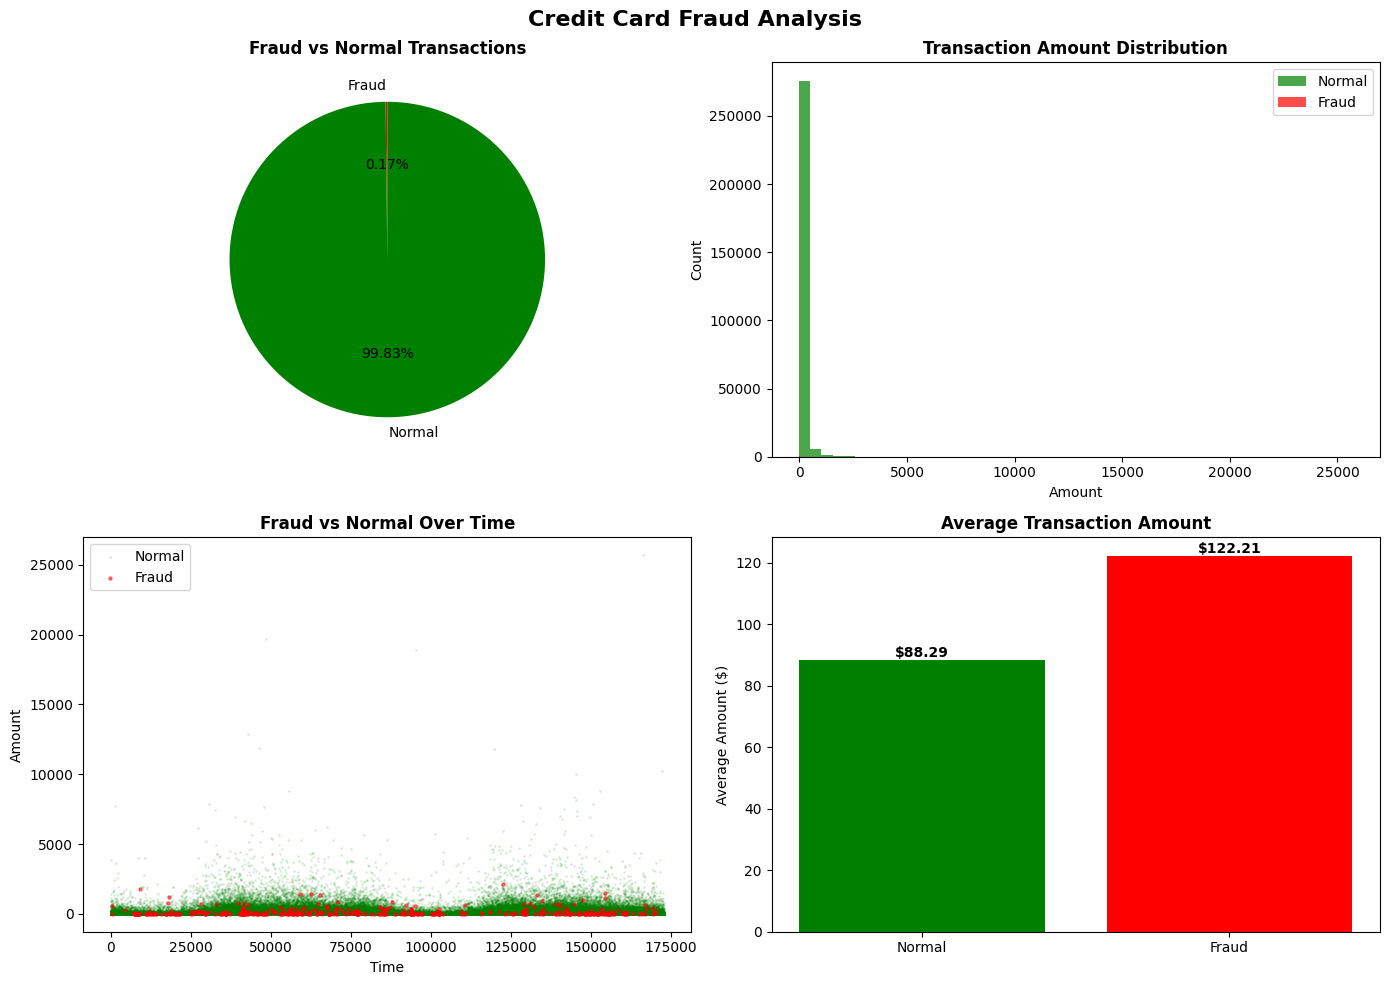

Visualizations saved!


In [19]:
fig, axes = plt.subplots(2, 2, figsize=(14,10))

# Chart 1 - Fraud vs Normal
axes[0,0].pie([df['Class'].sum(),
               (df['Class']==0).sum()],
              labels=['Fraud', 'Normal'],
              colors=['red','green'],
              autopct='%1.2f%%',
              startangle=90)
axes[0,0].set_title('Fraud vs Normal Transactions',
                    fontweight='bold')

# Chart 2 - Transaction Amount Distribution
axes[0,1].hist(df[df['Class']==0]['Amount'],
               bins=50, color='green',
               alpha=0.7, label='Normal')
axes[0,1].hist(df[df['Class']==1]['Amount'],
               bins=50, color='red',
               alpha=0.7, label='Fraud')
axes[0,1].set_title('Transaction Amount Distribution',
                    fontweight='bold')
axes[0,1].set_xlabel('Amount')
axes[0,1].set_ylabel('Count')
axes[0,1].legend()

# Chart 3 - Fraud by Time
axes[1,0].scatter(df[df['Class']==0]['Time'],
                  df[df['Class']==0]['Amount'],
                  alpha=0.1, color='green',
                  label='Normal', s=1)
axes[1,0].scatter(df[df['Class']==1]['Time'],
                  df[df['Class']==1]['Amount'],
                  alpha=0.5, color='red',
                  label='Fraud', s=5)
axes[1,0].set_title('Fraud vs Normal Over Time',
                    fontweight='bold')
axes[1,0].set_xlabel('Time')
axes[1,0].set_ylabel('Amount')
axes[1,0].legend()

# Chart 4 - Average Amount
avg_amounts = df.groupby('Class')['Amount'].mean()
axes[1,1].bar(['Normal','Fraud'],
              avg_amounts.values,
              color=['green','red'])
axes[1,1].set_title('Average Transaction Amount',
                    fontweight='bold')
axes[1,1].set_ylabel('Average Amount ($)')
for i, v in enumerate(avg_amounts.values):
    axes[1,1].text(i, v + 1, f'${v:.2f}',
                   ha='center', fontweight='bold')

plt.suptitle('Credit Card Fraud Analysis',
             fontsize=16, fontweight='bold')
plt.tight_layout()
plt.savefig('fraud_analysis.png', dpi=150,
            bbox_inches='tight')
plt.show()
print("Visualizations saved!")

In [20]:
# Prepare features
X = df.drop('Class', axis=1)
y = df['Class']

# Scale Amount and Time
scaler = StandardScaler()
X['Amount'] = scaler.fit_transform(
    X['Amount'].values.reshape(-1,1))
X['Time'] = scaler.fit_transform(
    X['Time'].values.reshape(-1,1))

# Split data
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2,
    random_state=42, stratify=y)

print(f"Training samples: {len(X_train):,}")
print(f"Testing samples: {len(X_test):,}")
print(f"Fraud in test: {y_test.sum():,}")
print("Data preparation complete!")

Training samples: 227,845
Testing samples: 56,962
Fraud in test: 98
Data preparation complete!


In [21]:
rf_model = RandomForestClassifier(
    n_estimators=50,
    max_depth=12,
    n_jobs=-1,
    random_state=42)

In [22]:
# 1. Train the model
rf_model.fit(X_train, y_train)

# 2. Generate predictions for evaluation
rf_pred = rf_model.predict(X_test)

In [24]:
from sklearn.metrics import roc_curve, roc_auc_score

# 1. Get predicted probabilities for the positive class (Fraud)
rf_probs = rf_model.predict_proba(X_test)[:, 1]

# 2. Calculate ROC curve and AUC score
fpr_rf, tpr_rf, _ = roc_curve(y_test, rf_probs)
rf_auc = roc_auc_score(y_test, rf_probs)

RANDOM FOREST — DETAILED RESULTS

Classification Report:
              precision    recall  f1-score   support

      Normal       1.00      1.00      1.00     56864
       Fraud       0.93      0.83      0.88        98

    accuracy                           1.00     56962
   macro avg       0.97      0.91      0.94     56962
weighted avg       1.00      1.00      1.00     56962



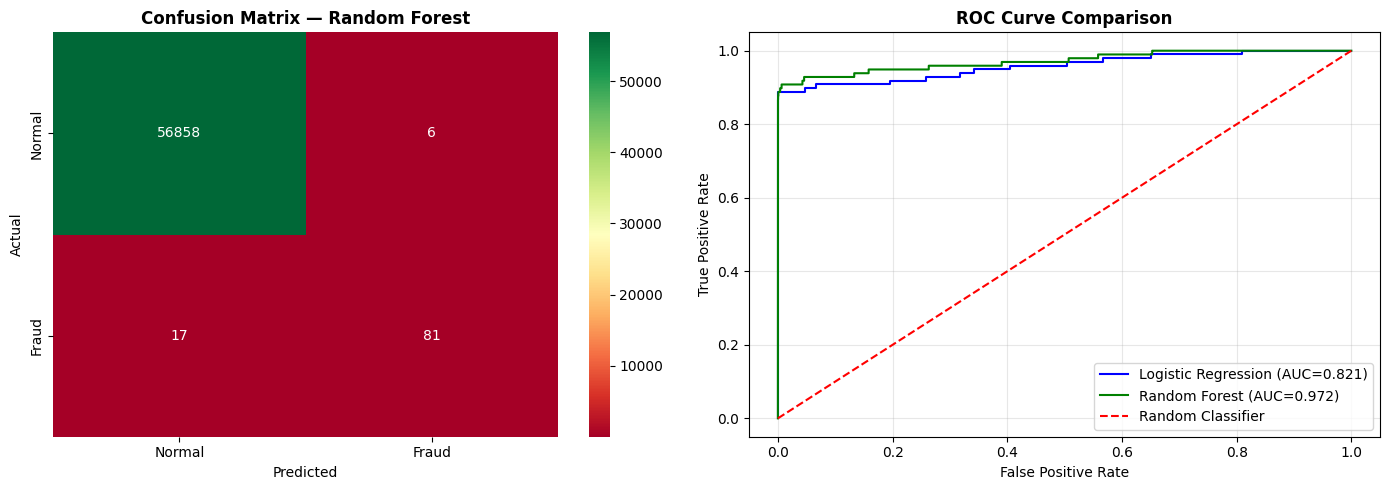

In [25]:
# Best model evaluation
print("=" * 50)
print("RANDOM FOREST — DETAILED RESULTS")
print("=" * 50)
print("\nClassification Report:")
print(classification_report(y_test, rf_pred,
      target_names=['Normal','Fraud']))

# Confusion Matrix
fig, axes = plt.subplots(1, 2, figsize=(14,5))

cm = confusion_matrix(y_test, rf_pred)
sns.heatmap(cm, annot=True, fmt='d',
            cmap='RdYlGn',
            xticklabels=['Normal','Fraud'],
            yticklabels=['Normal','Fraud'],
            ax=axes[0])
axes[0].set_title('Confusion Matrix — Random Forest',
                  fontweight='bold')
axes[0].set_ylabel('Actual')
axes[0].set_xlabel('Predicted')

# ROC Curve
fpr_lr, tpr_lr, _ = roc_curve(y_test,
    lr_model.predict_proba(X_test)[:,1])
fpr_rf, tpr_rf, _ = roc_curve(y_test,
    rf_model.predict_proba(X_test)[:,1])

axes[1].plot(fpr_lr, tpr_lr,
             label=f'Logistic Regression (AUC={lr_auc:.3f})',
             color='blue')
axes[1].plot(fpr_rf, tpr_rf,
             label=f'Random Forest (AUC={rf_auc:.3f})',
             color='green')
axes[1].plot([0,1],[0,1],
             linestyle='--', color='red',
             label='Random Classifier')
axes[1].set_title('ROC Curve Comparison',
                  fontweight='bold')
axes[1].set_xlabel('False Positive Rate')
axes[1].set_ylabel('True Positive Rate')
axes[1].legend()
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.savefig('model_results.png', dpi=150,
            bbox_inches='tight')
plt.show()

In [26]:
print("=" * 50)
print("LIVE FRAUD DETECTION DEMO")
print("=" * 50)

# Pick 3 fraud and 3 normal transactions from the test set
fraud_idx = y_test[y_test == 1].index[:3]
normal_idx = y_test[y_test == 0].index[:3]
idx = list(fraud_idx) + list(normal_idx)

X_sample = X_test.loc[idx]
actual = y_test.loc[idx].values

predictions = rf_model.predict(X_sample)
probabilities = rf_model.predict_proba(X_sample)[:, 1] * 100

print(f"{'Transaction':<14}{'Actual':<10}{'Predicted':<12}{'Fraud %':<10}")
print("-" * 46)
for i, (act, pred, prob) in enumerate(zip(actual, predictions, probabilities), 1):
    a = "FRAUD" if act == 1 else "Normal"
    p = "FRAUD" if pred == 1 else "Normal"
    mark = "OK" if act == pred else "WRONG"
    print(f"{i:<14}{a:<10}{p:<12}{prob:<9.1f}{mark}")

print("\nProject Complete! By Vijaya Lakshmi")

LIVE FRAUD DETECTION DEMO
Transaction   Actual    Predicted   Fraud %   
----------------------------------------------
1             FRAUD     FRAUD       100.0    OK
2             FRAUD     FRAUD       100.0    OK
3             FRAUD     FRAUD       82.0     OK
4             Normal    Normal      0.0      OK
5             Normal    Normal      0.0      OK
6             Normal    Normal      0.1      OK

Project Complete! By Vijaya Lakshmi
